# Guardar el ES contra underflow silencioso

Pregunta: ¿se puede detectar una pérdida numérica y recalcular desde los inputs originales? Hipótesis: los fallbacks coinciden con el oráculo racional y el camino ordinario conserva el baseline. Los métodos son conocidos; el aporte es el guard, sus políticas y el benchmark del repo. Pérdidas positivas, pesos conocidos y valores interpretados en binary64.

In [1]:
from src.guard import guarded_tail, TailUnderflowError
from src.sources import legacy
x, p = [1e308, 0.0], [1e-300, 1e300]
print('Baseline:', legacy.weighted_tail(x, .975, p).es)
r = guarded_tail(x, .975, p)
print('Protegido:', r.es, r.backend, r.fallback_reason)
assert r.es > 0
try:
    guarded_tail(x, .975, p, policy='raise')
except TailUnderflowError as error:
    print('Rechazo explícito:', error)

Baseline: 0.0
Protegido: 3.999999999999996e-291 fraction underflow encountered in divide
Rechazo explícito: underflow encountered in divide


## Experimento ejecutado

Se reutilizan 207 fixtures del aporte C++ y se añade un barrido de exponentes. El baseline real queda sin modificar. La referencia hinge usa Fraction sobre inputs binarios exactos; el fallback integra masa de cola en racionales. No son dos copias del mismo algoritmo.

In [2]:
import json, csv
from pathlib import Path
m=json.loads(Path('results/metadata.json').read_text())
print(m['summary'])
assert m['summary']['guard_lost_representable'] == 0
rows=list(csv.DictReader(Path('results/accuracy.csv').open()))
for row in rows:
    if row['reference_rounds_to_zero'] == 'True':
        print('Resultado no representable:', row['id'], row['output_rounds_to_zero'])

{'fixtures': 388, 'fallbacks': 107, 'baseline_lost_representable': 78, 'guard_lost_representable': 0, 'unrepresentable_final': 29, 'performance_rows': 168}
Resultado no representable: 262 True
Resultado no representable: 287 True
Resultado no representable: 292 True
Resultado no representable: 293 True
Resultado no representable: 312 True
Resultado no representable: 317 True
Resultado no representable: 318 True
Resultado no representable: 322 True
Resultado no representable: 323 True
Resultado no representable: 337 True
Resultado no representable: 342 True
Resultado no representable: 343 True
Resultado no representable: 347 True
Resultado no representable: 348 True
Resultado no representable: 352 True
Resultado no representable: 353 True
Resultado no representable: 354 True
Resultado no representable: 362 True
Resultado no representable: 367 True
Resultado no representable: 368 True
Resultado no representable: 372 True
Resultado no representable: 373 True
Resultado no representable: 37

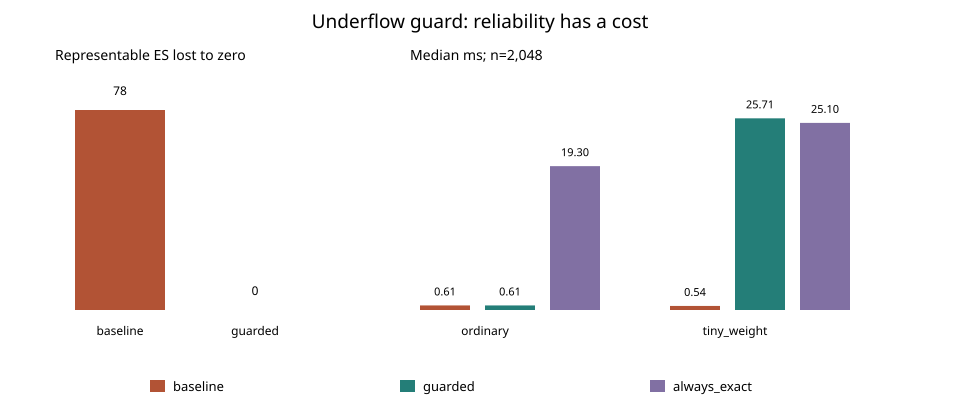

In [3]:
from IPython.display import SVG, display
display(SVG(filename='results/comparison.svg'))

## Conclusión crítica

La exactitud del fallback tiene costo: siempre-exacto es la ablación de velocidad. El guard no promete detectar todo error de redondeo. El presupuesto limita el fallback a 4096 filas; casos mayores se rechazan. Un ES racional no nulo puede redondear a cero al devolver float: se declara con un flag y se conserva la fracción. Sin inferencia sobre pronóstico, materialidad económica ni capital regulatorio. Ver informe.md y referencias.bib.